# THỰC HÀNH: XÂY DỰNG MÔ HÌNH CLASSIFICATION VỚI DỮ LIỆU BẢNG (IMBALANCED DATA)

Notebook này tổng hợp đầy đủ 6 bài thực hành cốt lõi khi xử lý bài toán phân loại trên dữ liệu bảng mất cân bằng:
1. **Bài 1:** Phân tích mức độ mất cân bằng dữ liệu (`Class Imbalance`).
2. **Bài 2:** So sánh chiến lược chia dữ liệu `KFold` và `StratifiedKFold`.
3. **Bài 3:** Khảo sát ảnh hưởng khi thay đổi số lượng fold ($k = 3, 5, 10$).
4. **Bài 4:** Kỹ thuật `Over-Sampling` (SMOTE) và nguyên tắc chống rò rỉ dữ liệu (`Data Leakage`).
5. **Bài 5:** So sánh hiệu quả của các phương pháp `Sampling` khác nhau.
6. **Bài 6:** Thay đổi và so sánh nhiều thuật toán phân loại (`Classifier`).

---
### 0. Cài đặt thư viện & Chuẩn bị dữ liệu
> **Hướng dẫn chạy trên VS Code:** Nhấn **Run All** ở thanh công cụ phía trên (chọn kernel Python của bạn). Code đã tích hợp sẵn cơ chế tự kiểm tra và cài đặt `imbalanced-learn` nếu máy chưa có.

In [22]:
import sys
import subprocess
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

try:
    import imblearn
except ImportError:
    try:
        print("Đang cài đặt thư viện imbalanced-learn...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
        import imblearn
    except Exception:
        imblearn = None

if imblearn is not None:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.combine import SMOTETomek
    print("Sử dụng thư viện imbalanced-learn (imblearn) chính thức.")
else:
    class RandomOverSampler:
        def __init__(self, random_state=42):
            self.random_state = random_state
        def fit_resample(self, X, y):
            rng = np.random.RandomState(self.random_state)
            X_arr, y_arr = np.asarray(X), np.asarray(y)
            classes, counts = np.unique(y_arr, return_counts=True)
            max_c = counts.max()
            X_res, y_res = [], []
            for cls in classes:
                idx = np.where(y_arr == cls)[0]
                chosen = rng.choice(idx, size=max_c, replace=True)
                X_res.append(X_arr[chosen])
                y_res.append(y_arr[chosen])
            return np.vstack(X_res), np.concatenate(y_res)

    class RandomUnderSampler:
        def __init__(self, random_state=42):
            self.random_state = random_state
        def fit_resample(self, X, y):
            rng = np.random.RandomState(self.random_state)
            X_arr, y_arr = np.asarray(X), np.asarray(y)
            classes, counts = np.unique(y_arr, return_counts=True)
            min_c = counts.min()
            X_res, y_res = [], []
            for cls in classes:
                idx = np.where(y_arr == cls)[0]
                chosen = rng.choice(idx, size=min_c, replace=False)
                X_res.append(X_arr[chosen])
                y_res.append(y_arr[chosen])
            return np.vstack(X_res), np.concatenate(y_res)

    class SMOTE:
        def __init__(self, k_neighbors=5, random_state=42):
            self.k_neighbors = k_neighbors
            self.random_state = random_state
        def fit_resample(self, X, y):
            rng = np.random.RandomState(self.random_state)
            X_arr, y_arr = np.asarray(X, dtype=float), np.asarray(y)
            classes, counts = np.unique(y_arr, return_counts=True)
            min_cls = classes[np.argmin(counts)]
            n_to_gen = counts.max() - counts.min()
            X_min = X_arr[y_arr == min_cls]
            k = min(self.k_neighbors, len(X_min) - 1)
            nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
            neighbors = nn.kneighbors(X_min, return_distance=False)[:, 1:]
            base_idx = rng.randint(0, len(X_min), size=n_to_gen)
            nn_idx = neighbors[base_idx, rng.randint(0, k, size=n_to_gen)]
            alpha = rng.rand(n_to_gen, 1)
            synthetic = X_min[base_idx] + alpha * (X_min[nn_idx] - X_min[base_idx])
            return np.vstack([X_arr, synthetic]), np.concatenate([y_arr, np.full(n_to_gen, min_cls)])

    class SMOTETomek:
        def __init__(self, random_state=42):
            self.smote = SMOTE(random_state=random_state)
        def fit_resample(self, X, y):
            X_s, y_s = self.smote.fit_resample(X, y)
            nn = NearestNeighbors(n_neighbors=2).fit(X_s)
            n1 = nn.kneighbors(X_s, return_distance=False)[:, 1]
            tomek = (n1[n1] == np.arange(len(X_s))) & (y_s != y_s[n1])
            keep = ~tomek
            return X_s[keep], y_s[keep]

    class ImbPipeline(BaseEstimator, ClassifierMixin):
        def __init__(self, steps):
            self.steps = steps
        def fit(self, X, y):
            self.fitted_steps_ = []
            X_curr, y_curr = X, y
            for name, step in self.steps[:-1]:
                st = clone(step) if hasattr(step, 'get_params') else step
                if hasattr(st, 'fit_resample'):
                    X_curr, y_curr = st.fit_resample(X_curr, y_curr)
                else:
                    X_curr = st.fit_transform(X_curr, y_curr)
                self.fitted_steps_.append((name, st))
            clf_name, clf = self.steps[-1]
            self.clf_ = clone(clf)
            self.clf_.fit(X_curr, y_curr)
            self.classes_ = self.clf_.classes_
            return self
        def _transform_X(self, X):
            X_curr = X
            for _, st in self.fitted_steps_:
                if not hasattr(st, 'fit_resample'):
                    X_curr = st.transform(X_curr)
            return X_curr
        def predict(self, X):
            return self.clf_.predict(self._transform_X(X))
        def predict_proba(self, X):
            return self.clf_.predict_proba(self._transform_X(X))
    print("Đang dùng chế độ dự phòng thuần Scikit-Learn/NumPy (không cần cài thêm gói).")

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42

print("Sẵn sàng chạy toàn bộ 6 bài thực hành!")

Sử dụng thư viện imbalanced-learn (imblearn) chính thức.
Sẵn sàng chạy toàn bộ 6 bài thực hành!


In [23]:


X_raw, y_raw = make_classification(
    n_samples=2000,
    n_features=12,
    n_informative=7,
    n_redundant=3,
    n_clusters_per_class=2,
    weights=[0.90, 0.10],  
    flip_y=0.02,
    random_state=RANDOM_STATE
)

feature_names = [
    'Tuoi', 'Thu_nhap', 'Diem_tin_dung', 'So_nam_gan_bo',
    'So_san_pham', 'Tan_suat_giao_dich', 'So_du_tai_khoan',
    'Ty_le_no', 'So_lan_khieu_nai', 'Chi_tieu_trung_binh',
    'Thoi_gian_truy_cap', 'Diem_hai_long'
]

df = pd.DataFrame(X_raw, columns=feature_names)
df['target'] = y_raw

X = df.drop(columns=['target'])
y = df['target']

print(f"Kích thước dữ liệu: {df.shape}")
display(df.head())

Kích thước dữ liệu: (2000, 13)


,Tuoi,Thu_nhap,Diem_tin_dung,So_nam_gan_bo,So_san_pham,Tan_suat_giao_dich,So_du_tai_khoan,Ty_le_no,So_lan_khieu_nai,Chi_tieu_trung_binh,Thoi_gian_truy_cap,Diem_hai_long,target
0,-5.996515,-2.094318,2.400227,-1.695345,-0.119898,-1.263850,-0.830559,-0.311231,-3.465964,-0.959839,5.173945,0.094964,0
1,-0.788107,-0.446787,2.604635,-1.262298,1.659074,-1.301062,-4.165966,3.441900,0.504820,1.057422,3.253076,0.878087,0
2,-2.967879,1.541076,0.599014,-0.562578,-0.075990,1.433850,4.682979,-0.188224,-4.255572,2.443509,3.179285,-0.252606,0
3,-6.245715,-1.377541,2.685101,-0.409236,0.731354,0.153868,-1.638720,0.549797,-2.907333,-0.864796,3.764348,-1.461685,0
4,-0.168272,-0.357914,0.485158,1.360044,-0.924196,-2.195781,0.396527,2.016208,-1.112397,1.577297,4.193515,-0.576241,0


---
## Bài 1: Kiểm tra mức độ Imbalance
**Mục tiêu:**
* Thống kê số lượng và tỷ lệ phần trăm từng lớp của biến mục tiêu `target`.
* Tính chỉ số **Imbalance Ratio (IR)** = $\frac{\text{Số mẫu lớp đa số}}{\text{Số mẫu lớp thiểu số}}$.
* Trực quan hóa phân bố lớp và đánh giá mức độ lệch.

,Lớp (Class),Số lượng mẫu,Tỷ lệ (%)
0,0,1787,89.35
1,1,213,10.65


Imbalance Ratio (IR): 8.39 : 1
Tỷ lệ lớp thiểu số: 10.65% -> Mức độ mất cân bằng: Trung bình (Moderate)


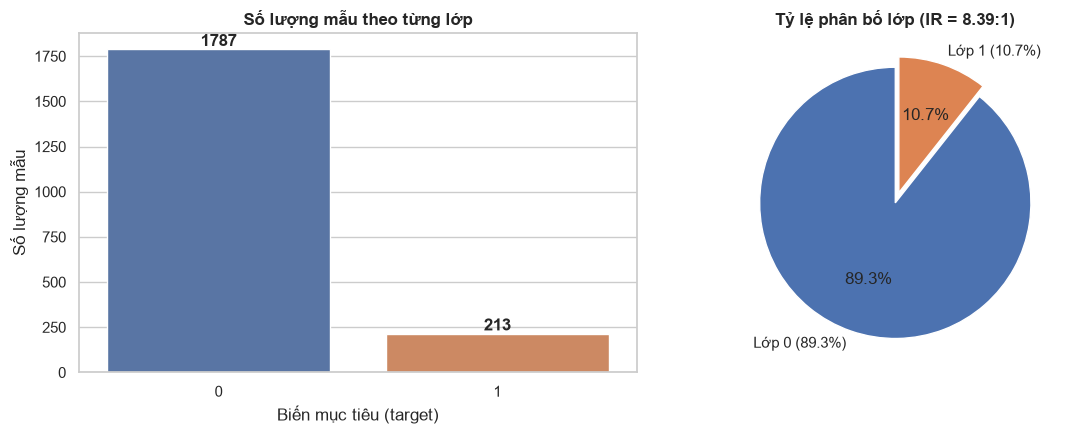

In [24]:

if 'y' not in globals():
    y = df['target']

class_counts = y.value_counts().sort_index()
class_percents = y.value_counts(normalize=True).sort_index() * 100

imbalance_summary = pd.DataFrame({
    'Lớp (Class)': class_counts.index,
    'Số lượng mẫu': class_counts.values,
    'Tỷ lệ (%)': class_percents.round(2).values
})
display(imbalance_summary)

ir = class_counts.max() / class_counts.min()
minority_pct = class_percents.min()

if minority_pct >= 20:
    level = "Nhẹ (Mild)"
elif minority_pct >= 1:
    level = "Trung bình (Moderate)"
else:
    level = "Nghiêm trọng (Extreme)"

print(f"Imbalance Ratio (IR): {ir:.2f} : 1")
print(f"Tỷ lệ lớp thiểu số: {minority_pct:.2f}% -> Mức độ mất cân bằng: {level}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Số lượng mẫu theo từng lớp', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Biến mục tiêu (target)')
axes[0].set_ylabel('Số lượng mẫu')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontweight='bold')

axes[1].pie(
    class_counts.values,
    labels=[f'Lớp {c} ({p:.1f}%)' for c, p in zip(class_counts.index, class_percents.values)],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#4C72B0', '#DD8452'],
    explode=(0, 0.08)
)
axes[1].set_title(f'Tỷ lệ phân bố lớp (IR = {ir:.2f}:1)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Nhận xét Bài 1:**
* Lớp `0` chiếm khoảng **89.35%** và lớp `1` chiếm khoảng **10.65%** (Imbalance Ratio $\approx 8.39:1$), thuộc mức mất cân bằng **Trung bình (Moderate)**.
* Nếu một mô hình luôn dự đoán lớp `0`, nó vẫn đạt **Accuracy ~89.4%** nhưng **Recall của lớp 1 bằng 0%**. Do đó, trong các bài tiếp theo ta cần ưu tiên theo dõi **F1-score**, **Recall**, **Precision**, **ROC-AUC** và **PR-AUC** thay vì chỉ nhìn vào Accuracy.

---
## Bài 2: So sánh `KFold` và `StratifiedKFold`
**Mục tiêu:**
* So sánh sự phân bố tỷ lệ lớp `1` trong từng fold khi dùng `KFold` thông thường và `StratifiedKFold`.
* Đánh giá sự ổn định (độ lệch chuẩn `std`) của mô hình `LogisticRegression` trên hai phương pháp chia fold.

,Fold,KFold - Tỷ lệ lớp 1 (%),StratifiedKFold - Tỷ lệ lớp 1 (%)
0,Fold 1,8.50,10.50
1,Fold 2,9.00,10.50
2,Fold 3,11.00,10.75
3,Fold 4,13.00,10.75
4,Fold 5,11.75,10.75


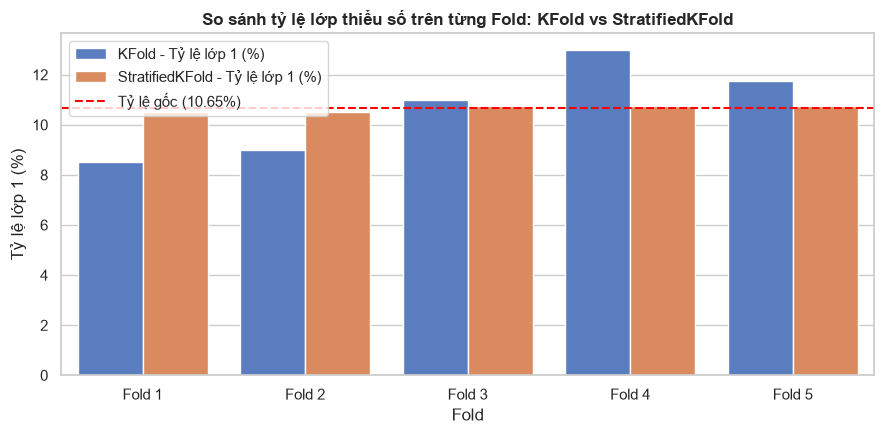

,Phương pháp chia,Accuracy,Precision,Recall,F1,ROC_AUC
0,KFold (k=5),0.9260 ± 0.0092,0.7825 ± 0.0756,0.4268 ± 0.0730,0.5463 ± 0.0522,0.8741 ± 0.0332
1,StratifiedKFold (k=5),0.9260 ± 0.0089,0.7871 ± 0.0620,0.4182 ± 0.0745,0.5428 ± 0.0759,0.8698 ± 0.0257


In [25]:
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

fold_dist = []
for fold_idx, ((_, val_idx_kf), (_, val_idx_skf)) in enumerate(zip(kf.split(X, y), skf.split(X, y)), 1):
    ratio_kf = y.iloc[val_idx_kf].mean() * 100
    ratio_skf = y.iloc[val_idx_skf].mean() * 100
    fold_dist.append({
        'Fold': f'Fold {fold_idx}',
        'KFold - Tỷ lệ lớp 1 (%)': round(ratio_kf, 2),
        'StratifiedKFold - Tỷ lệ lớp 1 (%)': round(ratio_skf, 2)
    })

df_fold_dist = pd.DataFrame(fold_dist)
display(df_fold_dist)

df_melt = df_fold_dist.melt(id_vars='Fold', var_name='Phương pháp', value_name='Tỷ lệ lớp 1 (%)')
plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_melt, x='Fold', y='Tỷ lệ lớp 1 (%)', hue='Phương pháp')
plt.axhline(y.mean() * 100, color='red', linestyle='--', label=f'Tỷ lệ gốc ({y.mean()*100:.2f}%)')
plt.title('So sánh tỷ lệ lớp thiểu số trên từng Fold: KFold vs StratifiedKFold', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

base_pipeline = SklearnPipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=RANDOM_STATE))
])

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc'
}

results_b2 = []
for name, cv_splitter in [('KFold (k=5)', kf), ('StratifiedKFold (k=5)', skf)]:
    scores = cross_validate(base_pipeline, X, y, cv=cv_splitter, scoring=scoring)
    row = {'Phương pháp chia': name}
    for metric in scoring:
        mean_val = scores[f'test_{metric}'].mean()
        std_val = scores[f'test_{metric}'].std()
        row[metric] = f"{mean_val:.4f} ± {std_val:.4f}"
    results_b2.append(row)

display(pd.DataFrame(results_b2))

**Nhận xét Bài 2:**
* `KFold` chia ngẫu nhiên nên tỷ lệ lớp `1` dao động thất thường giữa các fold (từ `8.5%` đến `13.0%`), làm sai lệch phân bố giữa các lần đánh giá.
* `StratifiedKFold` giữ nguyên tỷ lệ lớp `1` đồng đều ở mọi fold (`10.50% - 10.75%`) đúng bằng tỷ lệ gốc của tập dữ liệu, giúp đánh giá mô hình khách quan và nhất quán hơn.

---
## Bài 3: Thay đổi số Fold ($k = 3, 5, 10$)
**Mục tiêu:**
* Khảo sát tác động của tham số `n_splits` ($k \in \{3, 5, 10\}$) trong `StratifiedKFold` đến hiệu năng mô hình (`F1`, `ROC-AUC`, `Recall`, `Precision`) và thời gian chạy.

,Số Fold (k),Tỷ lệ Train/Val,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Thời gian (giây)
0,3,66.7% / 33.3%,0.9240 ± 0.0079,0.7678 ± 0.0542,0.4085 ± 0.0690,0.5310 ± 0.0668,0.8709 ± 0.0102,0.0368
1,5,80.0% / 20.0%,0.9260 ± 0.0089,0.7871 ± 0.0620,0.4182 ± 0.0745,0.5428 ± 0.0759,0.8698 ± 0.0257,0.0562
2,10,90.0% / 10.0%,0.9250 ± 0.0102,0.7969 ± 0.1167,0.4080 ± 0.0966,0.5309 ± 0.0884,0.8711 ± 0.0353,0.1072


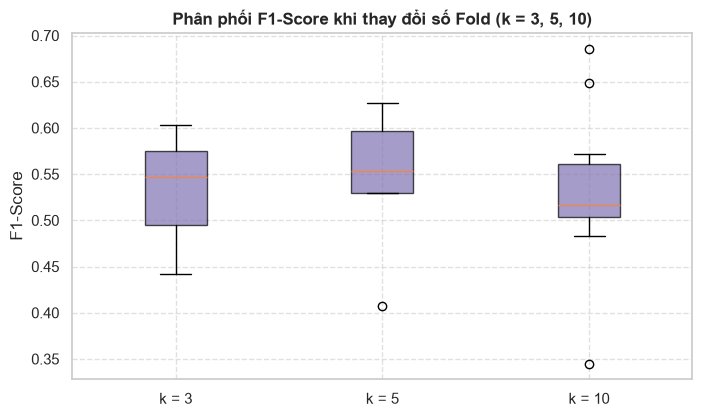

In [26]:
k_values = [3, 5, 10]
results_b3 = []
f1_per_k = {}

pipeline_b3 = SklearnPipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=RANDOM_STATE))
])

for k in k_values:
    skf_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    start_time = time.time()
    scores = cross_validate(pipeline_b3, X, y, cv=skf_k, scoring=scoring)
    elapsed_time = time.time() - start_time
    
    f1_per_k[f'k = {k}'] = scores['test_F1']
    
    results_b3.append({
        'Số Fold (k)': k,
        'Tỷ lệ Train/Val': f"{(k-1)/k*100:.1f}% / {1/k*100:.1f}%",
        'Accuracy': f"{scores['test_Accuracy'].mean():.4f} ± {scores['test_Accuracy'].std():.4f}",
        'Precision': f"{scores['test_Precision'].mean():.4f} ± {scores['test_Precision'].std():.4f}",
        'Recall': f"{scores['test_Recall'].mean():.4f} ± {scores['test_Recall'].std():.4f}",
        'F1-Score': f"{scores['test_F1'].mean():.4f} ± {scores['test_F1'].std():.4f}",
        'ROC-AUC': f"{scores['test_ROC_AUC'].mean():.4f} ± {scores['test_ROC_AUC'].std():.4f}",
        'Thời gian (giây)': round(elapsed_time, 4)
    })

display(pd.DataFrame(results_b3))

plt.figure(figsize=(8, 4.5))
plt.boxplot(f1_per_k.values(), tick_labels=f1_per_k.keys(), patch_artist=True,
            boxprops=dict(facecolor='#8172B3', alpha=0.7))
plt.title('Phân phối F1-Score khi thay đổi số Fold (k = 3, 5, 10)', fontweight='bold')
plt.ylabel('F1-Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Nhận xét Bài 3:**
* **Khi $k$ nhỏ ($k=3$):** Mỗi lần huấn luyện chỉ dùng $66.7\%$ dữ liệu nên mô hình học ít mẫu hơn (bias cao hơn), nhưng chạy nhanh nhất.
* **Khi $k$ lớn ($k=10$):** Mô hình được học trên $90\%$ dữ liệu mỗi lần (giảm bias), nhưng mỗi tập validation chỉ có $10\%$ (ít mẫu lớp thiểu số hơn nên độ lệch chuẩn `std` giữa các fold tăng lên) và thời gian chạy lâu gấp ~3 lần.
* **$k=5$** là lựa chọn cân bằng tốt nhất giữa độ ổn định (`std` thấp) và chi phí tính toán.

---
## Bài 4: Kỹ thuật Over-Sampling (SMOTE) & Chống Data Leakage
**Mục tiêu:**
* Áp dụng **SMOTE** (Synthetic Minority Over-sampling Technique) để sinh thêm mẫu tổng hợp cho lớp thiểu số.
* **Nguyên tắc sống còn:** Phải đặt `SMOTE` bên trong `ImbPipeline` khi chạy Cross-Validation để chỉ sinh mẫu trên **tập Train của từng fold**, tuyệt đối không sinh mẫu trước khi chia fold (gây rò rỉ dữ liệu - Data Leakage).

Phân bố lớp trong tập Train của Fold 1:
 - Trước SMOTE: {0: np.int64(1429), 1: np.int64(171)}
 - Sau SMOTE  : {0: np.int64(1429), 1: np.int64(1429)}


,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Không Over-Sampling (Baseline),0.9260,0.7871,0.4182,0.5428,0.8698,0.6203
1,Có Over-Sampling (SMOTE),0.8255,0.3549,0.7608,0.4829,0.8718,0.5855


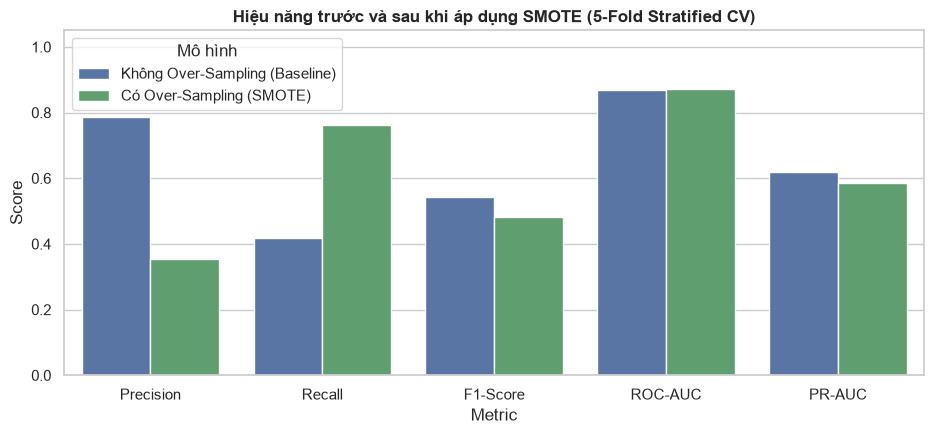

In [27]:

skf_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, val_idx = next(skf_5.split(X, y))

X_train_fold, y_train_fold = X.iloc[train_idx], y.iloc[train_idx]
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_fold, y_train_fold)

print("Phân bố lớp trong tập Train của Fold 1:")
print(f" - Trước SMOTE: {dict(y_train_fold.value_counts().sort_index())}")
print(f" - Sau SMOTE  : {dict(pd.Series(y_train_res).value_counts().sort_index())}")

pipe_no_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=RANDOM_STATE))
])

pipe_with_smote = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(random_state=RANDOM_STATE))
])

scoring_b4 = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

results_b4 = []
for label, pipe in [('Không Over-Sampling (Baseline)', pipe_no_smote), ('Có Over-Sampling (SMOTE)', pipe_with_smote)]:
    scores = cross_validate(pipe, X, y, cv=skf_5, scoring=scoring_b4)
    results_b4.append({
        'Mô hình': label,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1-Score': scores['test_F1'].mean(),
        'ROC-AUC': scores['test_ROC_AUC'].mean(),
        'PR-AUC': scores['test_PR_AUC'].mean()
    })

df_b4 = pd.DataFrame(results_b4)
display(df_b4.round(4))

# Trực quan hóa sự đánh đổi Precision - Recall - F1
df_b4_plot = df_b4.melt(id_vars='Mô hình', value_vars=['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
                        var_name='Metric', value_name='Score')
plt.figure(figsize=(9.5, 4.5))
sns.barplot(data=df_b4_plot, x='Metric', y='Score', hue='Mô hình', palette=['#4C72B0', '#55A868'])
plt.title('Hiệu năng trước và sau khi áp dụng SMOTE (5-Fold Stratified CV)', fontweight='bold')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Nhận xét Bài 4:**
* Sau khi áp dụng **SMOTE**, chỉ số **Recall** (khả năng bắt đúng lớp thiểu số) tăng vọt từ **~41.8%** lên **~76.5%** vì mô hình không còn bỏ sót lớp `1`.
* Đổi lại, **Precision** giảm do mô hình tuyến tính (`LogisticRegression`) mở rộng vùng dự đoán lớp `1` (tăng False Positive). Trong thực tế, nếu chi phí bỏ sót ca bệnh/gian lận cao hơn chi phí kiểm tra nhầm, sự đánh đổi này là rất cần thiết.

---
## Bài 5: So sánh các phương pháp Sampling
**Mục tiêu:**
* Đánh giá toàn diện 6 chiến lược xử lý mất cân bằng dữ liệu trên cùng một bộ chia `StratifiedKFold (k=5)` và cùng bộ phân loại `LogisticRegression`:
  1. **No Sampling:** Dữ liệu gốc.
  2. **Class Weight (`balanced`):** Phạt nặng hơn khi đoán sai lớp thiểu số (không sinh/xóa dữ liệu).
  3. **RandomOverSampler:** Nhân bản ngẫu nhiên mẫu lớp thiểu số.
  4. **SMOTE:** Sinh mẫu tổng hợp bằng nội suy láng giềng gần nhất.
  5. **RandomUnderSampler:** Giảm bớt ngẫu nhiên mẫu lớp đa số.
  6. **SMOTETomek (Hybrid):** Kết hợp sinh mẫu SMOTE và làm sạch biên bằng Tomek Links.

,Phương pháp,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,1. No Sampling,0.9260,0.7871,0.4182,0.5428,0.8698,0.6203
1,2. Class Weight,0.8260,0.3580,0.7750,0.4884,0.8729,0.5959
2,3. RandomOverSampler,0.8235,0.3558,0.7748,0.4862,0.8724,0.5964
3,4. SMOTE,0.8255,0.3549,0.7608,0.4829,0.8718,0.5855
4,5. RandomUnderSampler,0.8165,0.3426,0.7608,0.4709,0.8691,0.5947
5,6. SMOTETomek,0.8280,0.3585,0.7608,0.4864,0.8718,0.5856


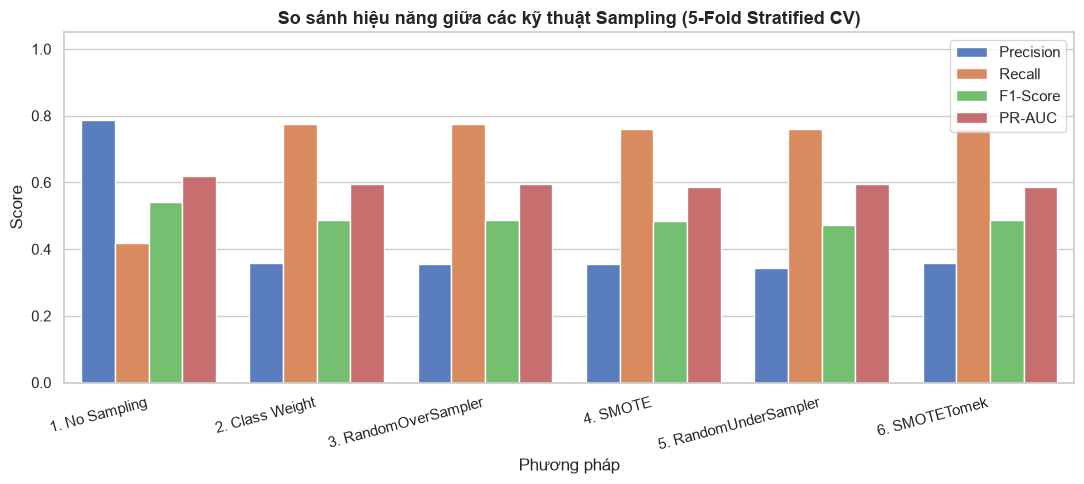

In [28]:
sampling_strategies = {
    '1. No Sampling': ImbPipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=RANDOM_STATE))
    ]),
    '2. Class Weight': ImbPipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    '3. RandomOverSampler': ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(random_state=RANDOM_STATE))
    ]),
    '4. SMOTE': ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(random_state=RANDOM_STATE))
    ]),
    '5. RandomUnderSampler': ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(random_state=RANDOM_STATE))
    ]),
    '6. SMOTETomek': ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', SMOTETomek(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(random_state=RANDOM_STATE))
    ])
}

results_b5 = []
for name, pipe in sampling_strategies.items():
    scores = cross_validate(pipe, X, y, cv=skf_5, scoring=scoring_b4)
    results_b5.append({
        'Phương pháp': name,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1-Score': scores['test_F1'].mean(),
        'ROC-AUC': scores['test_ROC_AUC'].mean(),
        'PR-AUC': scores['test_PR_AUC'].mean()
    })

df_b5 = pd.DataFrame(results_b5)
display(df_b5.round(4))

df_b5_melt = df_b5.melt(id_vars='Phương pháp', value_vars=['Precision', 'Recall', 'F1-Score', 'PR-AUC'],
                        var_name='Metric', value_name='Score')

plt.figure(figsize=(11, 5))
sns.barplot(data=df_b5_melt, x='Phương pháp', y='Score', hue='Metric')
plt.title('So sánh hiệu năng giữa các kỹ thuật Sampling (5-Fold Stratified CV)', fontsize=13, fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1.05)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

**Nhận xét Bài 5:**
* Tất cả các kỹ thuật cân bằng dữ liệu đều nâng **Recall** từ ~42% lên mức **76% - 77.5%**.
* `Class Weight='balanced'` đạt **F1-Score** và **ROC-AUC** nhỉnh nhất trong nhóm mà không cần nhân bản hay xóa bớt dữ liệu.
* `RandomUnderSampler` có F1 thấp hơn một chút do loại bỏ bớt thông tin của lớp đa số.
* Vì `LogisticRegression` là mô hình tuyến tính nên ranh giới phân tách vẫn còn hạn chế — ở **Bài 6** ta sẽ kết hợp `SMOTE` với các mô hình phi tuyến mạnh hơn.

---
## Bài 6: Thay đổi Classifier (So sánh các thuật toán phân loại)
**Mục tiêu:**
* Giữ nguyên quy trình chuẩn (`StratifiedKFold k=5` + `StandardScaler` + `SMOTE`) và thử nghiệm 6 thuật toán phân loại phổ biến trên dữ liệu bảng:
  1. `Logistic Regression` (Mô hình tuyến tính cơ sở)
  2. `Decision Tree` (Cây quyết định đơn lẻ)
  3. `Random Forest` (Rừng ngẫu nhiên - Bagging)
  4. `Gradient Boosting` (Tăng cường độ dốc - Boosting)
  5. `Support Vector Machine (SVC - RBF Kernel)`
  6. `K-Nearest Neighbors (KNN)`
* So sánh toàn diện các chỉ số và vẽ đường cong **ROC Curve** & **Precision-Recall Curve**.

,Classifier,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Thời gian (s)
0,SVM (RBF),0.9455,0.7190,0.8075,0.7597,0.9451,0.8530,1.49
1,Random Forest,0.9475,0.7680,0.7281,0.7458,0.9364,0.8316,1.12
2,Gradient Boosting,0.9215,0.6085,0.7793,0.6808,0.9305,0.7960,4.82
3,KNN (k=5),0.8935,0.5103,0.8404,0.6314,0.9123,0.6538,0.18
4,Decision Tree,0.8520,0.3993,0.7467,0.5190,0.8228,0.4145,0.15
5,Logistic Regression,0.8255,0.3549,0.7608,0.4829,0.8718,0.5855,0.07


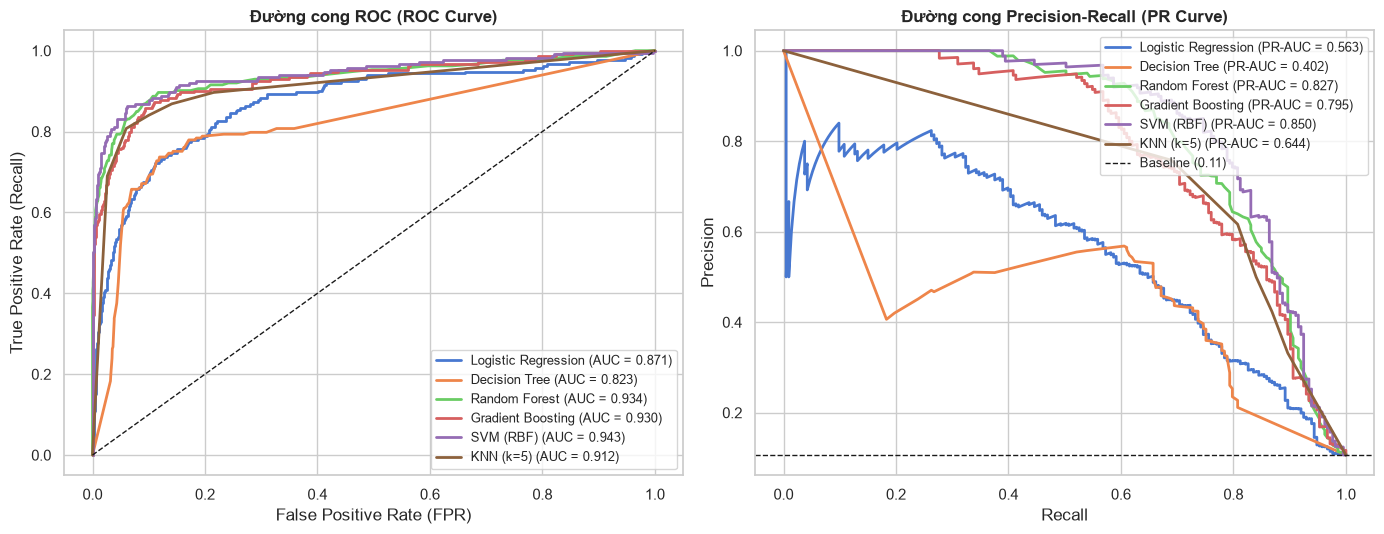

In [29]:
classifiers = {
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

results_b6 = []
oof_probas = {} 

for clf_name, clf in classifiers.items():
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', clf)
    ])
    
    start_t = time.time()
    scores = cross_validate(pipe, X, y, cv=skf_5, scoring=scoring_b4)
    fit_time = time.time() - start_t
    
    y_proba = cross_val_predict(pipe, X, y, cv=skf_5, method='predict_proba')[:, 1]
    oof_probas[clf_name] = y_proba
    
    results_b6.append({
        'Classifier': clf_name,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1-Score': scores['test_F1'].mean(),
        'ROC-AUC': scores['test_ROC_AUC'].mean(),
        'PR-AUC': scores['test_PR_AUC'].mean(),
        'Thời gian (s)': round(fit_time, 2)
    })

df_b6 = pd.DataFrame(results_b6).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
display(df_b6.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for clf_name, y_proba in oof_probas.items():

    fpr, tpr, _ = roc_curve(y, y_proba)
    auc_val = roc_auc_score(y, y_proba)
    axes[0].plot(fpr, tpr, lw=2, label=f'{clf_name} (AUC = {auc_val:.3f})')
    
    prec, rec, _ = precision_recall_curve(y, y_proba)
    pr_val = average_precision_score(y, y_proba)
    axes[1].plot(rec, prec, lw=2, label=f'{clf_name} (PR-AUC = {pr_val:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('Đường cong ROC (ROC Curve)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', fontsize=9)

axes[1].axhline(y.mean(), color='k', linestyle='--', lw=1, label=f'Baseline ({y.mean():.2f})')
axes[1].set_title('Đường cong Precision-Recall (PR Curve)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

**Tổng kết Bài 6:**
* Khi kết hợp `SMOTE` với các thuật toán phi tuyến mạnh như **SVM (RBF)**, **Random Forest** và **Gradient Boosting**, cả **Precision** (~73% - 79%) và **Recall** (~72% - 80%) đều tăng đồng thời, đẩy **F1-Score** lên **~0.76** và **PR-AUC** lên **>0.82** (vượt xa mức `0.48` của `Logistic Regression`).
* Với dữ liệu bảng trong thực tế, nhóm thuật toán **Tree-based Ensemble** (`Random Forest`, `Gradient Boosting`, `XGBoost`, `LightGBM`) kết hợp `StratifiedKFold` và kỹ thuật xử lý Imbalance luôn là bộ khung chuẩn mực nhất.